# Part 1 — Energy variables across global warming levels

Mean-state changes of the energy resource/demand across **+1.5 / +2.0 / +3.0 °C** (RCP8.5,
9 EURO-CORDEX chains), to set up Part 2 (extremes). **+1.5 °C = reference (absolute)**; **% change**
at +2.0 / +3.0 °C. Annual and seasonal (meteorological DJF/MAM/JJA/SON). Every figure is a **map**
showing the **ensemble central value** (`ENSEMBLE_STAT`), with sign-agreement stippling on % change.

- **View A — raw resource:** PV + onshore-wind **capacity factors** as raw **gridded maps**; offshore
  wind CF, hydropower (ROR + reservoir inflow, GWh) and heating/cooling **demand** (raw c2e, GWh) as
  **country choropleths**.
- **View B — TYNDP generation (per country):** TYNDP capacities applied to the aggregated CFs →
  generation (GWh), **PV / onshore / offshore separate**, per-country choropleths.

Gridded CF maps consume `energy/analysis/{annual,seasonal}/gwl/mean_gwl_{15,20,30}*.nc` produced by
`scripts/compute_energy_means_gwl.py` (run that first).

## 0 · Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

from cordex2energy.conversion_energy.tyndp import (
    load_tyndp_supply_capacities, load_tyndp_country_codes, build_c2e_name_to_iso2,
    compute_estimated_generation, preprocess_hydro_ror, load_nuts_geodata,
)
from cordex2energy_analysis.extremes_analysis import resolve_gwl_period_definitions
from cordex2energy_analysis.plotting import (
    plot_ensemble_mean, plot_ensemble_mean_change,
    plot_ensemble_mean_seasonal, plot_ensemble_mean_change_seasonal,
)
from cordex2energy_analysis.analysis import compute_sign_agreement

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [2]:
paths = json.load(open("../paths.json"))
path_data_processed = Path(paths["path_data_processed"])
path_energy_europe  = path_data_processed / "energy" / "europe"
path_c2e            = path_data_processed / "c2e" / "outputs"
path_tyndp          = path_data_processed / "extremes" / "tyndp"

# ── Common configuration (identical across the three source notebooks) ──────
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "LOW"
supply_year      = 2050
rolling_window_residual_load = 1
use_reservoir_hydro    = True
use_batteries          = True
use_prosumer_batteries = True
# Utility batteries only (prosumer is always heuristic + country-level):
flexibility_scheme = "market"         # "market" (per-asset market operation) | "system" (lumped, annual QP)
battery_dispatch_method = "optimal"   # "heuristic" | "optimal" (rolling day-ahead QP)  [market only]
utility_dispatch_level  = "zone"      # "zone" (pooled over the 6 balancing zones) | "country"  [market only]

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"
    if flexibility_scheme == "system":
        run_tag += "_sysflex"
    else:
        if battery_dispatch_method == "optimal":
            run_tag += "_optbatt"
        if utility_dispatch_level == "country":
            run_tag += "_utilcountry"

turbine          = "E-126/7580"
turbine_fn       = turbine.replace("/", "_")
WARMING_LEVELS   = [1.5, 2.0, 3.0]
season_order     = ["DJF", "MAM", "JJA", "SON"]
season_map = {12:"DJF",1:"DJF",2:"DJF",3:"MAM",4:"MAM",5:"MAM",6:"JJA",7:"JJA",8:"JJA",9:"SON",10:"SON",11:"SON"}

# Ensemble central statistic for all maps: "mean" (default; matches analyse_energy) or "median".
ENSEMBLE_STAT = "mean"
_reduce = (lambda da: da.mean("model")) if ENSEMBLE_STAT == "mean" else (lambda da: da.median("model"))

In [3]:
# Model chains available for rcp85 (match Part 2): derive from the PV tyndp_agg files
_pv_files = sorted((path_energy_europe / "pv").glob(f"*_{climate_scenario}/pv_tyndp_agg_*.nc"))
models = ["_".join(p.stem.split("pv_tyndp_agg_")[1].split("_")[:-1]) for p in _pv_files]  # drop trailing _rcpNN
print(f"{len(models)} models:", models)

period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=climate_scenario,
)
GWL_LABELS = list(period_defs.keys())            # ['+1.5°C', '+2.0°C', '+3.0°C']
REF_LABEL  = GWL_LABELS[0]
for lbl in GWL_LABELS:
    print(f"  {lbl}: {len(period_defs[lbl])}/{len(models)} models")

9 models: ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1', 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1', 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1', 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1', 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1', 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1', 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']
  +1.5°C: 9/9 models
  +2.0°C: 9/9 models
  +3.0°C: 9/9 models


In [4]:
# TYNDP capacities + country-name mapping (View B)
df_solar, df_wind_on, df_wind_off = load_tyndp_supply_capacities(
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
_country_codes = load_tyndp_country_codes(path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb")
C2E_NAME_TO_ISO2 = build_c2e_name_to_iso2(_country_codes)
_SUPPLY_COL = {"LOW":"LOW","BE":"Best Estimate","HIGH":"HIGH"}[supply_scenario]

In [5]:
# Country GeoDataFrame from Natural Earth admin-0 (every country in the extent, incl. the UK,
# so no-data countries are still outlined/greyed rather than left blank).
# Effective ISO2 = ISO_A2, falling back to ISO_A2_EH where ISO_A2 == '-99' (France, Norway,
# Kosovo->XK, ...). Natural Earth codes the UK 'GB' but the c2e data uses 'UK' -> remap GB->UK.
_EXTENT = (-12, 40, 33, 72)  # lon_min, lon_max, lat_min, lat_max
_ne = gpd.read_file(path_data_processed / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson")
_iso = _ne["ISO_A2"].where(_ne["ISO_A2"] != "-99", _ne["ISO_A2_EH"]).replace({"GB": "UK"})
gdf_countries = (_ne.assign(ISO2=_iso)[["ISO2", "geometry"]]
                 .dissolve(by="ISO2").reset_index()
                 .cx[_EXTENT[0]:_EXTENT[1], _EXTENT[2]:_EXTENT[3]])

def plot_country_choropleth(series_by_iso2, title, cmap="viridis", vcenter=None,
                            vmin=None, vmax=None, clabel="", ax=None, extend="neither", legend=True):
    # Choropleth of a per-ISO2 pandas Series on the country polygons.
    vals = series_by_iso2.rename("val").rename_axis("ISO2").reset_index()
    merged = gdf_countries.merge(vals, on="ISO2", how="left")
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 7))
    kw = dict(vmin=vmin, vmax=vmax)
    if vcenter is not None:
        from matplotlib.colors import TwoSlopeNorm
        lo = vmin if vmin is not None else float(np.nanmin(merged["val"]))
        hi = vmax if vmax is not None else float(np.nanmax(merged["val"]))
        kw = dict(norm=TwoSlopeNorm(vcenter=vcenter, vmin=min(lo, vcenter-1e-6), vmax=max(hi, vcenter+1e-6)))
    merged.plot(column="val", cmap=cmap, legend=legend, ax=ax,
                legend_kwds={"label": clabel, "shrink": 0.6, "extend": extend},
                missing_kwds={"color": "lightgrey", "label": "no data"},
                edgecolor="black", linewidth=0.5, **kw)
    ax.set_xlim(_EXTENT[0], _EXTENT[1]); ax.set_ylim(_EXTENT[2], _EXTENT[3])
    ax.set_axis_off(); ax.set_title(title, fontsize=10)
    return ax

## 1 · Helpers — per-model GWL-window period means

In [6]:
def _period_reduce(da, aggregation, method):
    # Reduce a (country,time)/(lat,lon,time) DataArray over time to an annual or per-season
    # climatological value. method: "sum" (totals) or "mean" (capacity factors).
    if aggregation == "annual":
        yearly = (da.resample(time="YE").sum("time") if method == "sum"
                  else da.resample(time="YE").mean("time"))
        return yearly.mean("time")
    # seasonal (meteorological): per (year, season) then average over years
    seas = xr.DataArray([season_map[m] for m in pd.DatetimeIndex(da["time"].values).month],
                        coords={"time": da["time"]}, dims="time")
    yr = da["time"].dt.year
    grouped = da.groupby(xr.DataArray(
        [f"{y}-{s}" for y, s in zip(yr.values, seas.values)], coords={"time": da["time"]}, dims="time"))
    agg = grouped.sum("time") if method == "sum" else grouped.mean("time")
    lab = agg["group"].values.astype(str)
    agg = agg.assign_coords(season=("group", [x.split("-")[1] for x in lab])).groupby("season").mean("group")
    return agg.reindex(season=season_order)

def country_gwl_field(da_by_model_window, aggregation, method):
    # {model: (country,time) sliced to its GWL window} -> PER-MODEL (model, country[, season]).
    # NOT ensemble-reduced (the grid plotter reduces for display and counts sign agreement).
    per_model = []
    for m, da in da_by_model_window.items():
        per_model.append(_period_reduce(da, aggregation, method).expand_dims(model=[m]))
    return xr.concat(per_model, dim="model")

## 2 · View A — energy resource & demand grid

Rows = energy quantity, columns = global warming level. Column 1 = **+1.5 °C absolute**; columns 2-3 = **% change** vs +1.5 °C (diverging, centred on 0). Gridded capacity-factor rows (PV, onshore wind) and c2e country choropleth rows (hydro ROR + reservoir inflow, heating + cooling demand) share one figure. Ensemble central value = `ENSEMBLE_STAT`.

In [7]:
# Fast wide-CSV parser (pandas is very slow on ~300k-column CSVs; row-wise numpy is ~14x faster).
def _read_wide_fast(path):
    with open(path) as fh:
        times = pd.to_datetime(fh.readline().rstrip("\n").split(",")[1:])
        countries, rows = [], []
        for line in fh:
            i = line.index(",")
            countries.append(line[:i])
            rows.append(np.fromstring(line[i + 1:], sep=",", dtype=np.float32))
    return countries, times, np.vstack(rows)

def _model_prefix(m):
    return "_".join(m.split("_")[:-1])   # drop ensemble member -> c2e folder key

# Convert the c2e wide CSVs to compact per-variable NetCDF ONCE (dims: model, country, time),
# then reuse on every later run. Native temporal resolution (no 3-hourly upsampling):
#   hydro_ror    = daily  (GWh/day)
#   hydro_inflow = weekly (GWh/week)
#   heating/cooling = 3-hourly GW summed to daily GWh.
_C2E_CACHE_DIR = path_data_processed / "energy" / "analysis" / "c2e_cache"

def _load_c2e_var(name, kind):
    f = _C2E_CACHE_DIR / f"c2e_{name}_{climate_scenario}.nc"
    if f.exists():
        return xr.open_dataarray(f)
    print(f"  building cache {f.name} (one-time) ...")
    _C2E_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    per_model = []
    for m in models:
        pre = _model_prefix(m); d = path_c2e / pre / "output_variables"
        fn = f"{name}_CORDEX_{pre}_85.csv" if kind == "hydro" else f"{name}-demand_CORDEX_{pre}_85.csv"
        countries, times, arr = _read_wide_fast(d / fn)
        da = xr.DataArray(arr, dims=["country", "time"],
                          coords={"country": [C2E_NAME_TO_ISO2.get(c, c) for c in countries], "time": times})
        if kind == "demand":
            da = (da * 3.0).resample(time="D").sum("time")   # GW (3-hourly) -> GWh/day
        per_model.append(da.expand_dims(model=[m]))
    out = xr.concat(per_model, dim="model", join="outer").astype("float32")
    out.name = name
    out.to_netcdf(f)
    return out

_c2e_ds = {
    "hydro_ror":    _load_c2e_var("hydro_ror",    "hydro"),    # daily  GWh/day
    "hydro_inflow": _load_c2e_var("hydro_inflow", "hydro"),    # weekly GWh/week
    "heating":      _load_c2e_var("heating",      "demand"),   # daily  GWh
    "cooling":      _load_c2e_var("cooling",      "demand"),   # daily  GWh
}
print("c2e datasets ready:", {k: dict(v.sizes) for k, v in _c2e_ds.items()})

c2e datasets ready: {'hydro_ror': {'model': 9, 'country': 6, 'time': 39785}, 'hydro_inflow': {'model': 9, 'country': 10, 'time': 5688}, 'heating': {'model': 9, 'country': 37, 'time': 40177}, 'cooling': {'model': 9, 'country': 37, 'time': 40177}}


In [8]:
# --- Field accessors return PER-MODEL fields (model, ...); plotter reduces + counts agreement ---
import matplotlib.colors as mcolors
# Colour scheme matches analyse_energy.ipynb (CMAPS in cordex2energy_analysis.plotting); all CVD-safe.
river_cmap = mcolors.LinearSegmentedColormap.from_list(
    "river", ["#1c4e80", "#4ea3c8", "#cfe9f2", "#ffffff"])
_gwl_grid_cache = {}
_GRID_SEASON_RENAME = {"Winter": "DJF", "Spring": "MAM", "Summer": "JJA", "Fall": "SON"}
def _load_gwl_grid(aggregation):
    if aggregation in _gwl_grid_cache:
        return _gwl_grid_cache[aggregation]
    suffix = "_meteorological" if aggregation == "seasonal" else ""
    out = {}
    for wl, lbl in zip(WARMING_LEVELS, GWL_LABELS):
        f = path_data_processed / "energy" / "analysis" / aggregation / "gwl" / f"mean_gwl_{int(round(wl*10))}{suffix}.nc"
        if f.exists():
            _ds = xr.open_dataset(f)
            if "season" in _ds.coords:   # grid files use Winter/Spring/Summer/Fall
                _ds = _ds.assign_coords(season=[_GRID_SEASON_RENAME.get(str(s), str(s))
                                                for s in _ds["season"].values])
            out[lbl] = _ds
        else:
            out[lbl] = None
    _gwl_grid_cache[aggregation] = out
    return out

def _grid_field(key, label, aggregation):
    ds = _load_gwl_grid(aggregation)[label]
    return None if ds is None else ds[key]                    # (model, lat, lon[, season])

def _country_field(var, label, aggregation):
    by_model = {}
    for m in models:
        win = period_defs[label].get(m)
        if win is None:
            continue
        by_model[m] = _c2e_ds[var].sel(model=m, time=slice(str(win[0]), str(win[1])))
    return country_gwl_field(by_model, aggregation, "sum")    # (model, country[, season])

VIEWA_UNIT   = "TWh"                          # energy unit for View A country rows: "TWh" or "GWh"
_VIEWA_SCALE = 1e-3 if VIEWA_UNIT == "TWh" else 1.0
_a = lambda fn: (lambda l, a: fn(l, a) * _VIEWA_SCALE)   # scale a country energy field to VIEWA_UNIT
_QUANTS_A = [
    ("Solar power", "grid",    lambda l, a: _grid_field("pv",   l, a),          "plasma",   "CF"),
    ("Wind power",    "grid",    lambda l, a: _grid_field("wind", l, a),          "Greens",   "CF"),
    ("Run-of-river hydro", "country", _a(lambda l, a: _country_field("hydro_ror",    l, a)), "Blues", VIEWA_UNIT),
    ("Reservoir inflow",   "country", _a(lambda l, a: _country_field("hydro_inflow", l, a)), "Blues", VIEWA_UNIT),
    ("Heating demand",     "country", _a(lambda l, a: _country_field("heating",      l, a)), "Blues",  VIEWA_UNIT),
    ("Cooling demand",     "country", _a(lambda l, a: _country_field("cooling",      l, a)), "YlOrRd", VIEWA_UNIT),
]

In [9]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# % change colorbar extent — limit it so a few tiny-baseline cells don't wash out the map:
PCT_CLIP_PCTILE = 98      # per-row robust percentile for the %-change scale (None -> data max)
PCT_CLIP_CAP    = None    # optional HARD cap in % (e.g. 100 -> fixed ±100 %); overrides percentile
# Model-agreement hatching on %-change cells: hatch where fewer than this fraction agree on the sign.
AGREEMENT_FRAC  = 2/3
_ROBUST_N = int(np.ceil(len(models) * AGREEMENT_FRAC))
plt.rcParams["hatch.linewidth"] = 0.5   # visible black hatch, as in analyse_energy.ipynb

def _hatch(ax, kind, agree, field):
    # Hatch where < _ROBUST_N models agree on sign — but only where there is data (finite value).
    if agree is None or field is None:
        return
    if kind == "grid":
        dis = ((agree.values < _ROBUST_N) & np.isfinite(field.values)).astype(float)
        hov = ax.contourf(agree["lon"].values, agree["lat"].values, dis, levels=[0.5, 1.5],
                          colors="none", hatches=["///"], zorder=3)
        hov.set_edgecolor("black"); hov.set_linewidth(0)
    else:
        isos = [str(z) for z, a, v in zip(agree["country"].values, agree.values, field.values)
                if a < _ROBUST_N and np.isfinite(v)]
        if isos:
            gdf_countries[gdf_countries["ISO2"].isin(isos)].plot(
                ax=ax, facecolor="none", edgecolor="black", hatch="///", linewidth=0.0, zorder=3)

def _draw_cell(ax, kind, field, cmap, vcenter=None, vmin=None, vmax=None, clabel="",
               extend="neither", colorbar=True, agree=None):
    if field is None:                       # gridded means not built yet
        ax.text(0.5, 0.5, "run\ncompute_energy_means_gwl.py", ha="center", va="center",
                fontsize=8, color="0.55", transform=ax.transAxes)
        ax.set_axis_off(); return
    if kind == "grid":
        norm = TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax) if vcenter is not None else None
        pcm = ax.pcolormesh(field["lon"].values, field["lat"].values, field.values, cmap=cmap,
                            norm=norm, vmin=(None if norm else vmin), vmax=(None if norm else vmax),
                            shading="auto")
        gdf_countries.boundary.plot(ax=ax, color="0.5", linewidth=0.15)
        _hatch(ax, kind, agree, field)
        if colorbar:
            cb = plt.colorbar(pcm, ax=ax, shrink=0.62, pad=0.02, extend=extend)
            cb.set_label(clabel, fontsize=7); cb.ax.tick_params(labelsize=6)
        ax.set_xlim(_EXTENT[0], _EXTENT[1]); ax.set_ylim(_EXTENT[2], _EXTENT[3])
        ax.set_axis_off(); ax.set_aspect("auto")   # geopandas forces equal aspect -> squeezed maps
    else:
        plot_country_choropleth(field.to_series().dropna(), "", cmap=cmap, vcenter=vcenter,
                                vmin=vmin, vmax=vmax, clabel=clabel, ax=ax, extend=extend, legend=colorbar)
        _hatch(ax, kind, agree, field)
        ax.set_aspect("auto")   # geopandas (choropleth + hatch) forces equal aspect -> squeezed

def _row_pct_vmax(chgs):
    arrs = [np.abs(c.values[np.isfinite(c.values)]).ravel() for c in chgs if c is not None]
    vals = np.concatenate(arrs) if arrs else np.array([1.0])
    if vals.size == 0:
        return 1.0, "neither"
    data_max = float(vals.max())
    if PCT_CLIP_CAP is not None:
        vmax = float(PCT_CLIP_CAP)
    elif PCT_CLIP_PCTILE is not None:
        vmax = float(np.nanpercentile(vals, PCT_CLIP_PCTILE))
    else:
        vmax = data_max
    vmax = max(vmax, 1e-6)
    return vmax, ("both" if data_max > vmax * 1.0001 else "neither")

def plot_gwl_grid(quants, aggregation, season=None, suptitle=""):
    # rows = quantities, columns = GWL. col 0 = absolute (+1.5 °C); cols 1.. = % change vs +1.5 °C,
    # one shared colorbar per row, hatched where < 2/3 of models agree on the sign of change.
    ncol = len(GWL_LABELS)
    fig, axes = plt.subplots(len(quants), ncol, figsize=(4.0 * ncol, 2.9 * len(quants)),
                             squeeze=False, constrained_layout=True)
    for r, _q in enumerate(quants):
        name, kind, field_fn, cmap, unit = _q[:5]
        abs_center = _q[5] if len(_q) > 5 else None   # e.g. 0 -> diverging absolute panel
        ref_pm = field_fn(REF_LABEL, aggregation)
        if season is not None and ref_pm is not None and "season" in ref_pm.dims:
            ref_pm = ref_pm.sel(season=season)
        ref = _reduce(ref_pm) if ref_pm is not None else None
        if abs_center is not None and ref is not None and np.isfinite(ref.values).any():
            _av = max(float(np.nanpercentile(np.abs(ref.values[np.isfinite(ref.values)]), PCT_CLIP_PCTILE)), 1e-6)
            _draw_cell(axes[r, 0], kind, ref, cmap, vcenter=abs_center, vmin=-_av, vmax=_av,
                       clabel=unit, extend="both", colorbar=True)
        else:
            _draw_cell(axes[r, 0], kind, ref, cmap, clabel=unit, colorbar=True)
        chgs, agrees = [], []
        for lbl in GWL_LABELS[1:]:
            t_pm = field_fn(lbl, aggregation)
            if t_pm is not None and ref_pm is not None:
                if season is not None and "season" in t_pm.dims:
                    t_pm = t_pm.sel(season=season)
                chg_pm = (100 * (t_pm - ref_pm) / ref_pm)
                chg_pm = chg_pm.where(np.isfinite(chg_pm))
                chgs.append(_reduce(chg_pm))
                agrees.append(compute_sign_agreement(chg_pm, model_dim="model"))
            else:
                chgs.append(None); agrees.append(None)
        vmax, extend = _row_pct_vmax(chgs)
        for ci, (ch, ag) in enumerate(zip(chgs, agrees), start=1):
            _draw_cell(axes[r, ci], kind, ch, "RdBu", vcenter=0, vmin=-vmax, vmax=vmax,
                       clabel="% change", extend=extend, colorbar=False, agree=ag)
        if any(c is not None for c in chgs):
            sm = ScalarMappable(norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax), cmap="RdBu")
            sm.set_array([])
            cb = fig.colorbar(sm, ax=[axes[r, c] for c in range(1, ncol)], fraction=0.02, pad=0.01, extend=extend)
            cb.set_label("% change", fontsize=8); cb.ax.tick_params(labelsize=7)
        axes[r, 0].set_ylabel(name, fontsize=10, fontweight="bold", labelpad=6)
        axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        for _sp in axes[r, 0].spines.values():
            _sp.set_visible(False)
    for ci, lbl in enumerate(GWL_LABELS):
        axes[0, ci].set_title(lbl if ci == 0 else f"{lbl}  (% vs {REF_LABEL})", fontsize=11, fontweight="bold")
    fig.suptitle(suptitle + "   (hatch = <2/3 models agree on sign)", fontsize=12, fontweight="bold")
    plt.show()

In [10]:
# plot_gwl_grid(_QUANTS_A, "annual",
#                suptitle="View A — annual (absolute at +1.5 °C, % change at +2.0/+3.0 °C)")

In [11]:
# for _s in season_order:
#     plot_gwl_grid(_QUANTS_A, "seasonal", season=_s, suptitle=f"View A — {_s}")

## 3 · View B — TYNDP-scenario energy balance per country

All quantities from the same saved residual-load run (demand DE/2050, supply LOW/2050): **PV / onshore / offshore wind generation**, **run-of-river & reservoir hydro**, **heating & cooling demand**, and the resulting **residual load** (demand − renewable generation − hydro/storage dispatch; positive = deficit, negative = surplus, diverging scale centred on 0). Same grid: absolute at +1.5 °C, % change at +2.0/+3.0 °C.

In [12]:
# --- View B: sourced from the saved TYNDP residual-load pipeline (per country) ---------------
# Generation, hydro, demand and residual load all come from the SAME run so View B is internally
# consistent. Produced by scripts/compute_tyndp_projections_extremes.py (demand DE/2050, supply LOW/2050).
_RL_DIR = path_data_processed / "extremes" / "residual_load"

def _load_rl(m):
    d = _RL_DIR / f"{m}_{climate_scenario}" / run_tag
    return xr.merge([xr.open_dataset(d / "residual_load.nc"),
                     xr.open_dataset(d / "components.nc")])          # (country, time), lazy
_rl_cache = {m: _load_rl(m) for m in models}
print("Opened residual-load output for", len(_rl_cache), "models |", run_tag)

def _rl_field(var, label, aggregation):
    by_model = {}
    for m in models:
        win = period_defs[label].get(m)
        if win is None:
            continue
        by_model[m] = _rl_cache[m][var].sel(time=slice(str(win[0]), str(win[1])))
    return country_gwl_field(by_model, aggregation, "sum")            # (model, country[, season])

def _rl_field_nz(var, label, aggregation):
    # As _rl_field, but countries with no capacity (structural 0) -> NaN, so they are greyed
    # out (missing_kwds) rather than drawn as 0 (white) on the sequential absolute panel.
    f = _rl_field(var, label, aggregation)
    return f.where(f != 0)

# (name, kind, field_fn, cmap, unit[, abs_center]); abs_center=0 -> diverging absolute panel.
VIEWB_UNIT   = "TWh"                          # energy unit for View B: "TWh" or "GWh"
_VIEWB_SCALE = 1e-3 if VIEWB_UNIT == "TWh" else 1.0
_b = lambda fn: (lambda l, a: fn(l, a) * _VIEWB_SCALE)   # scale an energy field to VIEWB_UNIT
_QUANTS_B = [
    ("PV generation",            "country", _b(lambda l, a: _rl_field("gen_pv",                 l, a)), "plasma",   VIEWB_UNIT),
    ("Onshore wind generation",  "country", _b(lambda l, a: _rl_field("gen_wind_on",            l, a)), "Greens",   VIEWB_UNIT),
    ("Offshore wind generation", "country", _b(lambda l, a: _rl_field_nz("gen_wind_off",        l, a)), "Greens",   VIEWB_UNIT),
    ("Run-of-river hydro",       "country", _b(lambda l, a: _rl_field_nz("gen_hydro_ror",       l, a)), "Blues",    VIEWB_UNIT),
    ("Reservoir hydro",          "country", _b(lambda l, a: _rl_field_nz("reservoir_dispatch_gwh", l, a)), "Blues", VIEWB_UNIT),
    ("Reservoir inflow",         "country", _b(lambda l, a: _country_field("hydro_inflow",       l, a)), "PuBu",   VIEWB_UNIT),
    ("Heating demand",           "country", _b(lambda l, a: _country_field("heating",           l, a)), "Blues",    VIEWB_UNIT),
    ("Cooling demand",           "country", _b(lambda l, a: _country_field("cooling",           l, a)), "YlOrRd",   VIEWB_UNIT),
    ("Residual load",            "country", _b(lambda l, a: _rl_field("residual_load",          l, a)), "RdBu_r",   VIEWB_UNIT, 0),
]

Opened residual-load output for 9 models | DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_optbatt


/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

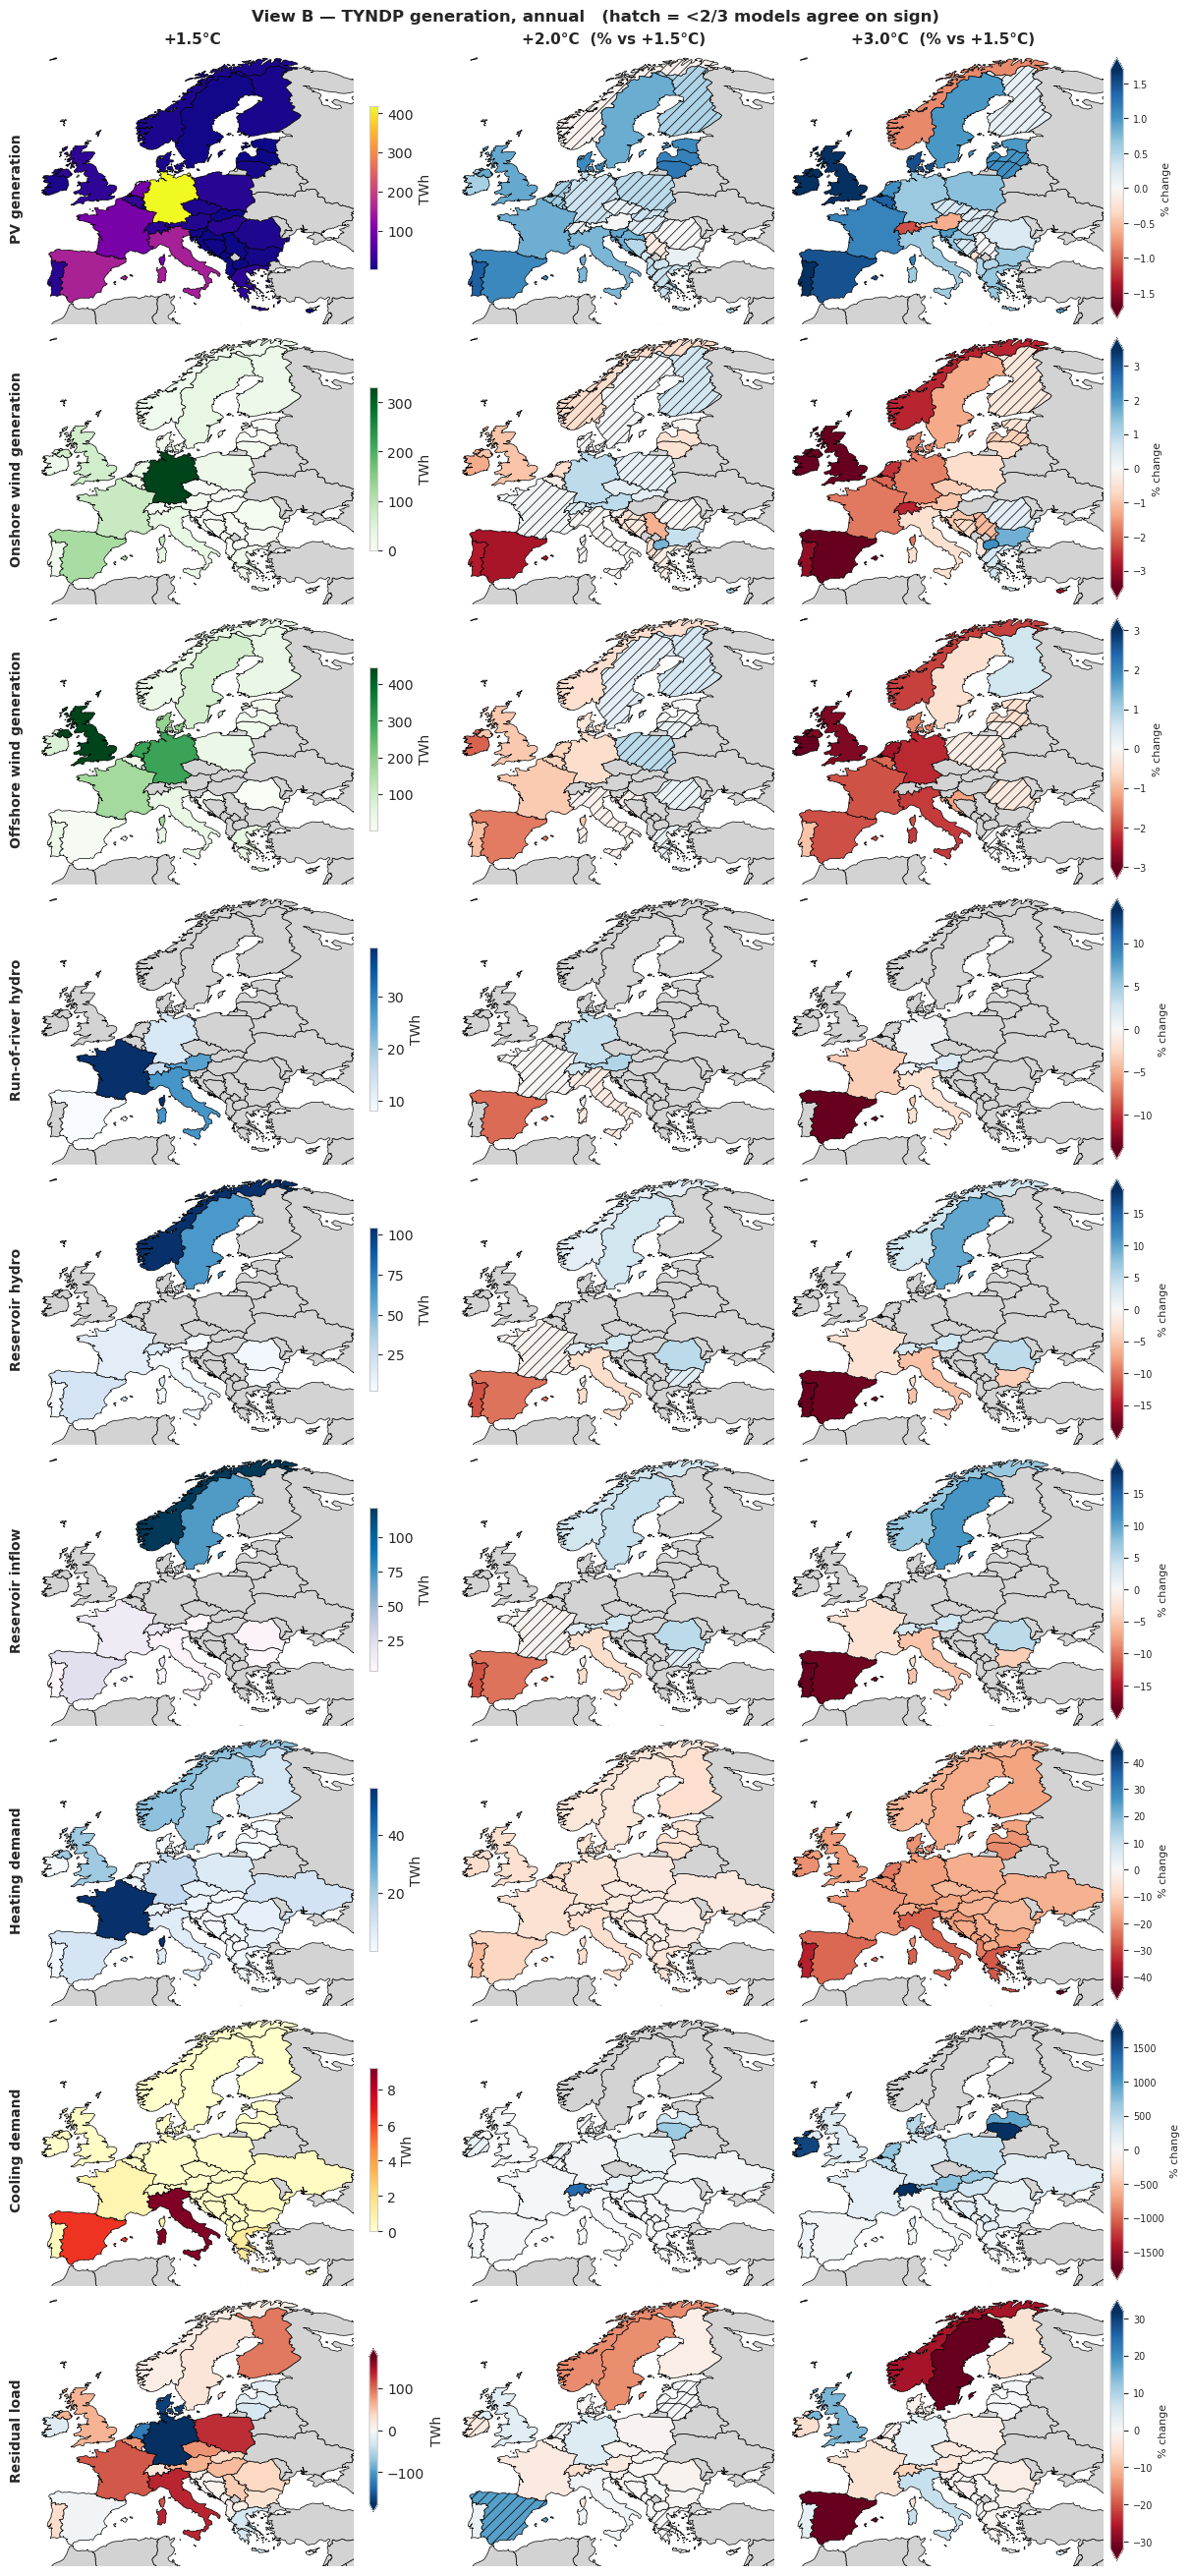

In [13]:
plot_gwl_grid(_QUANTS_B, "annual",
               suptitle="View B — TYNDP generation, annual")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

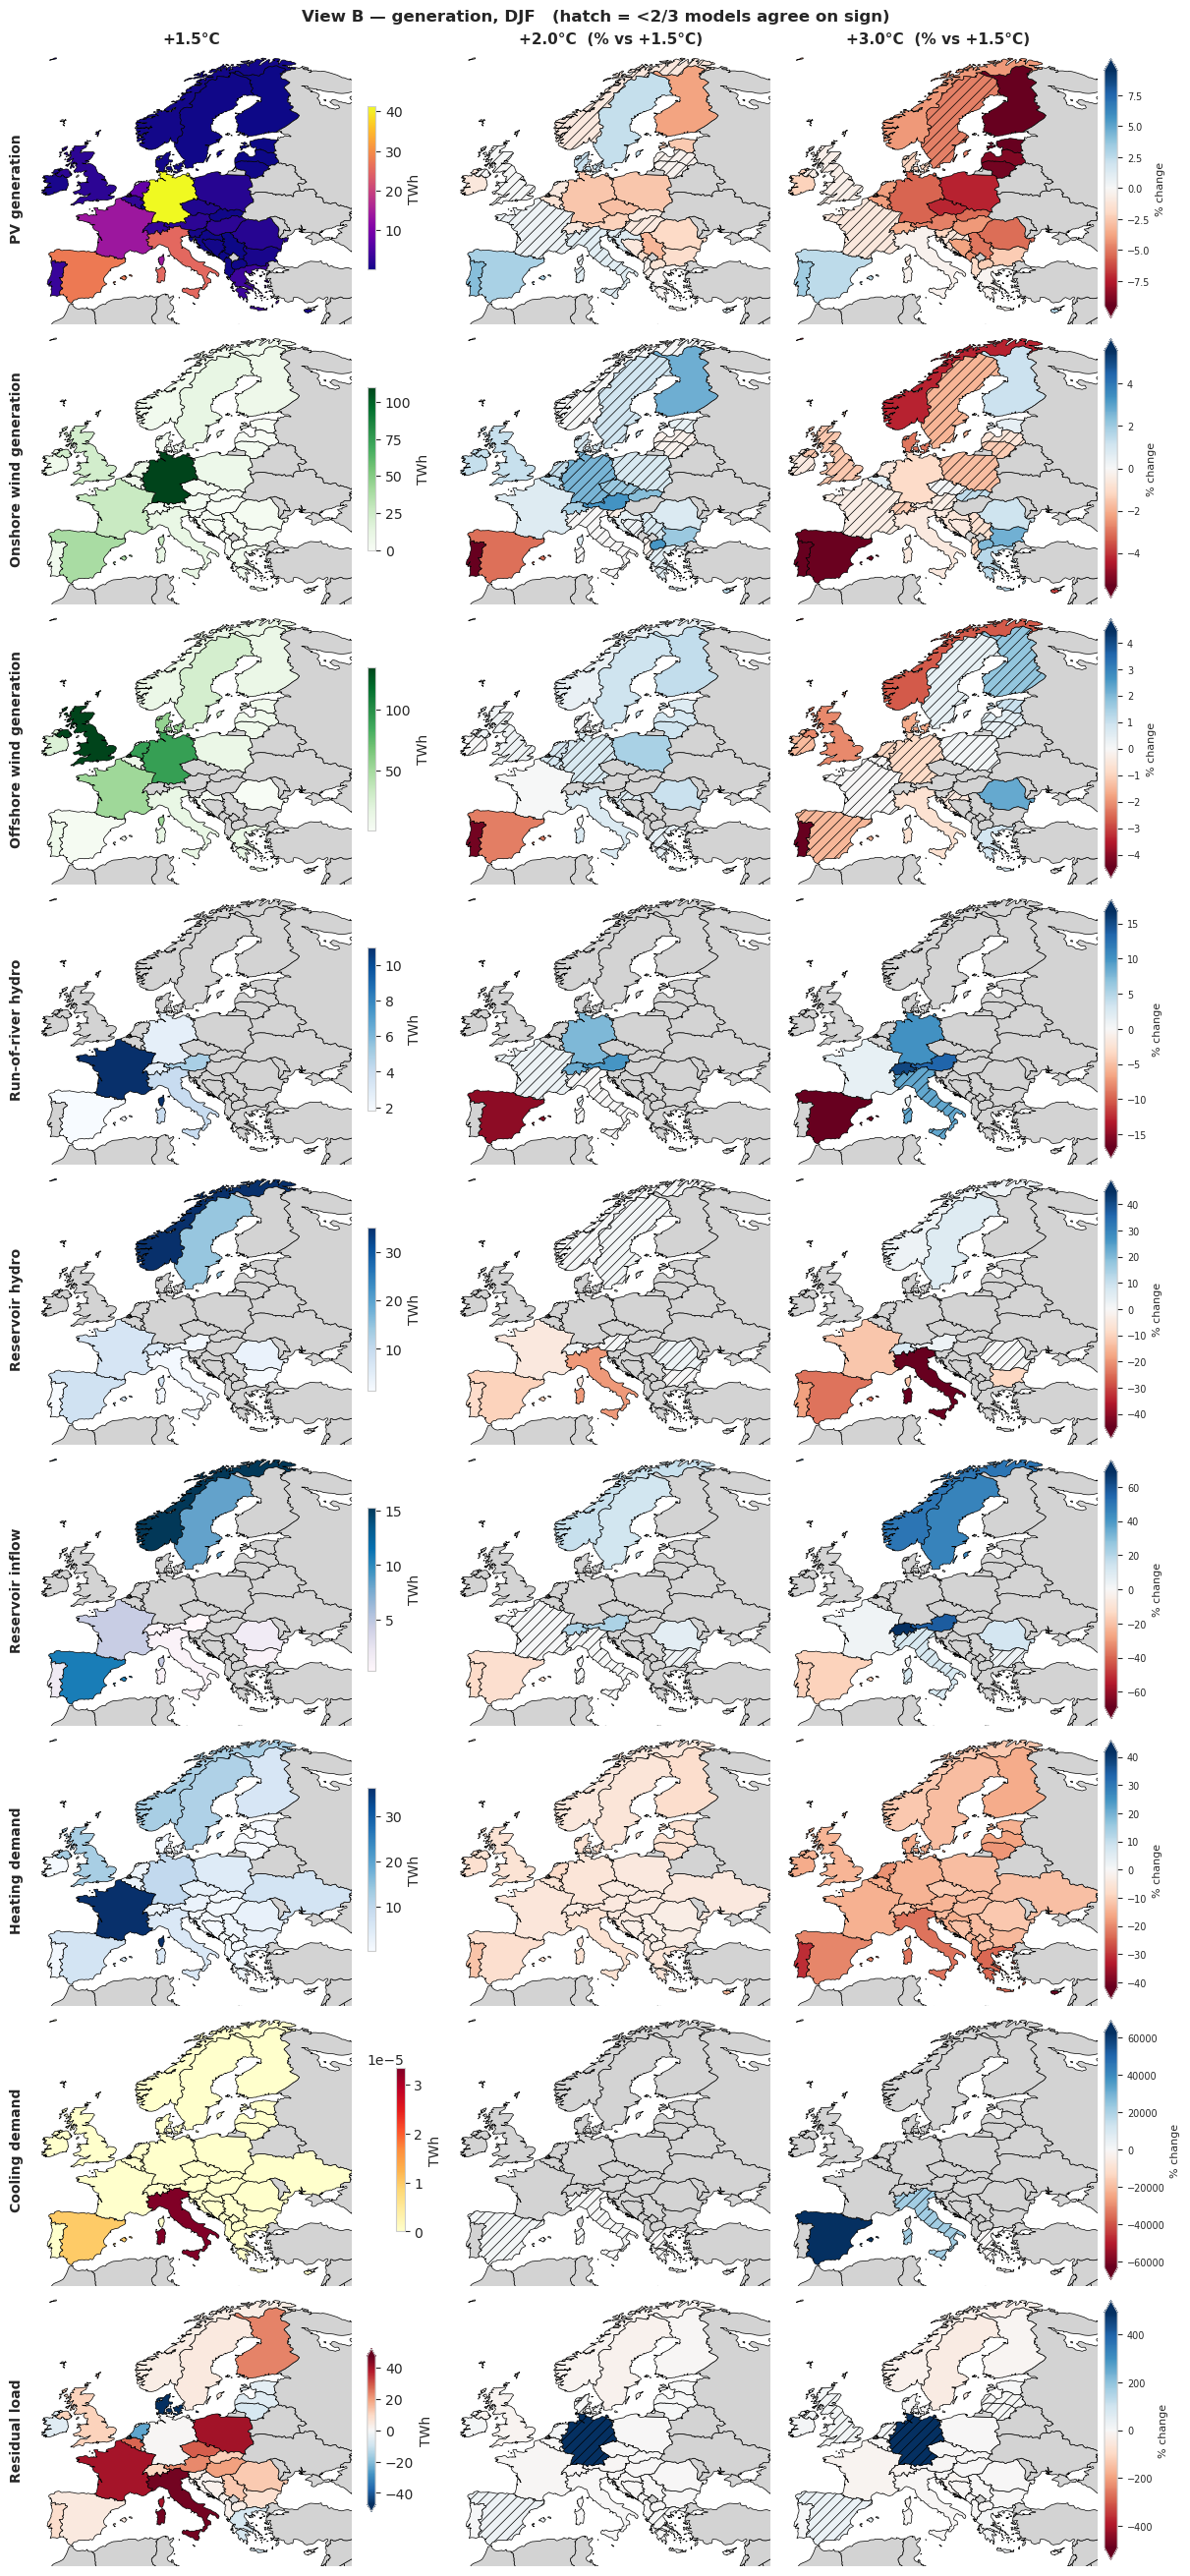

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

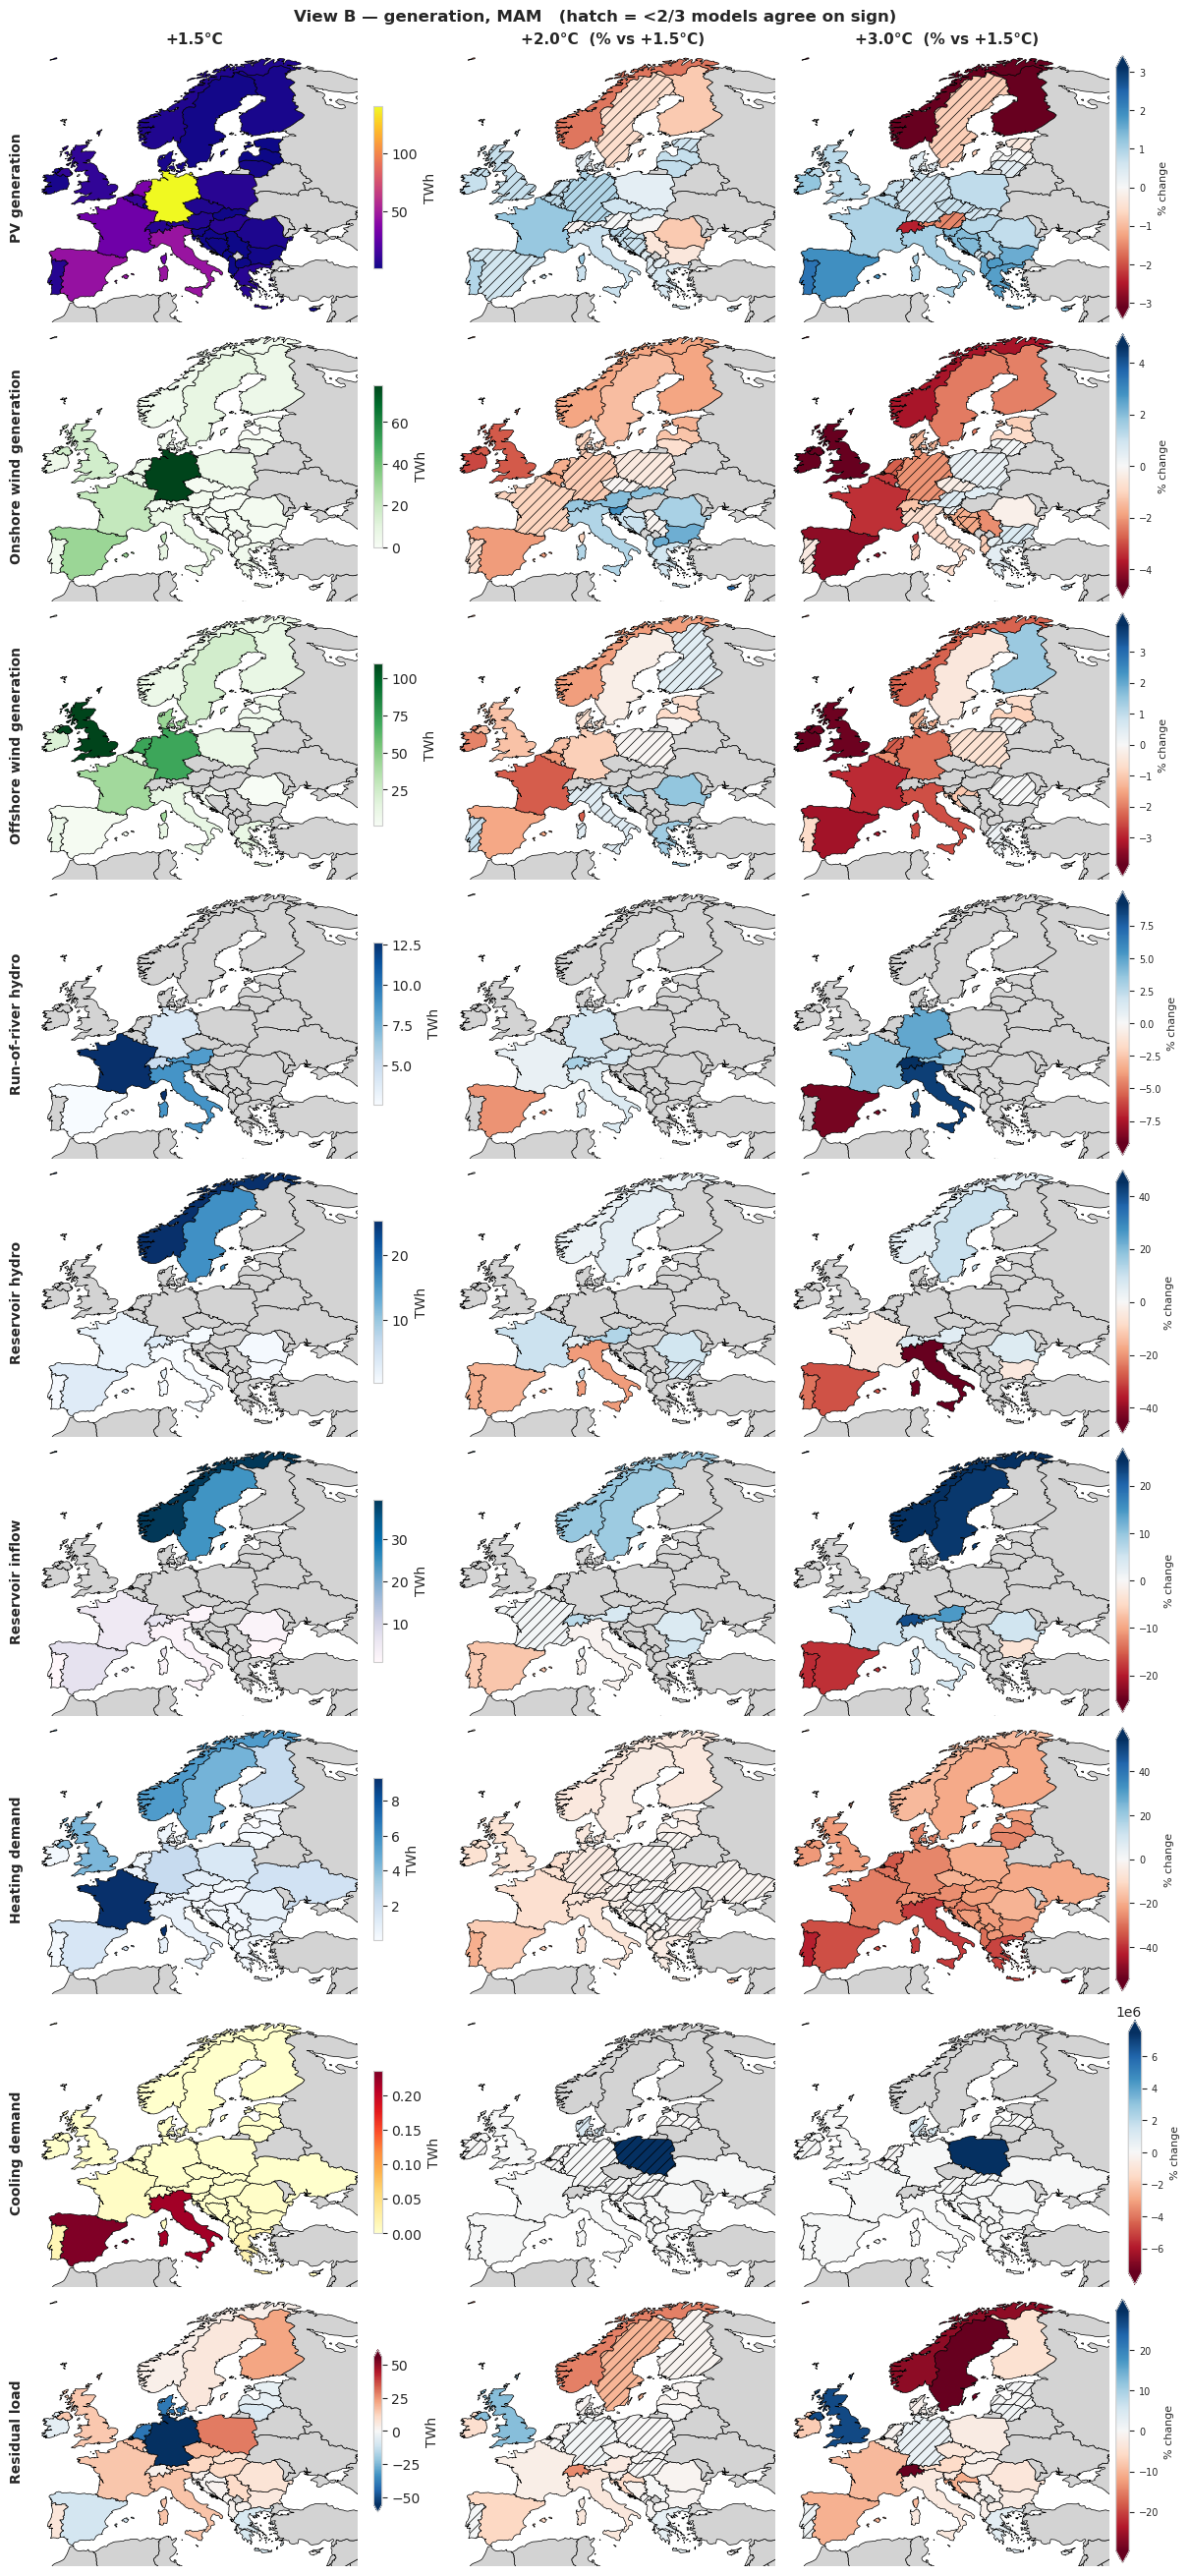

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

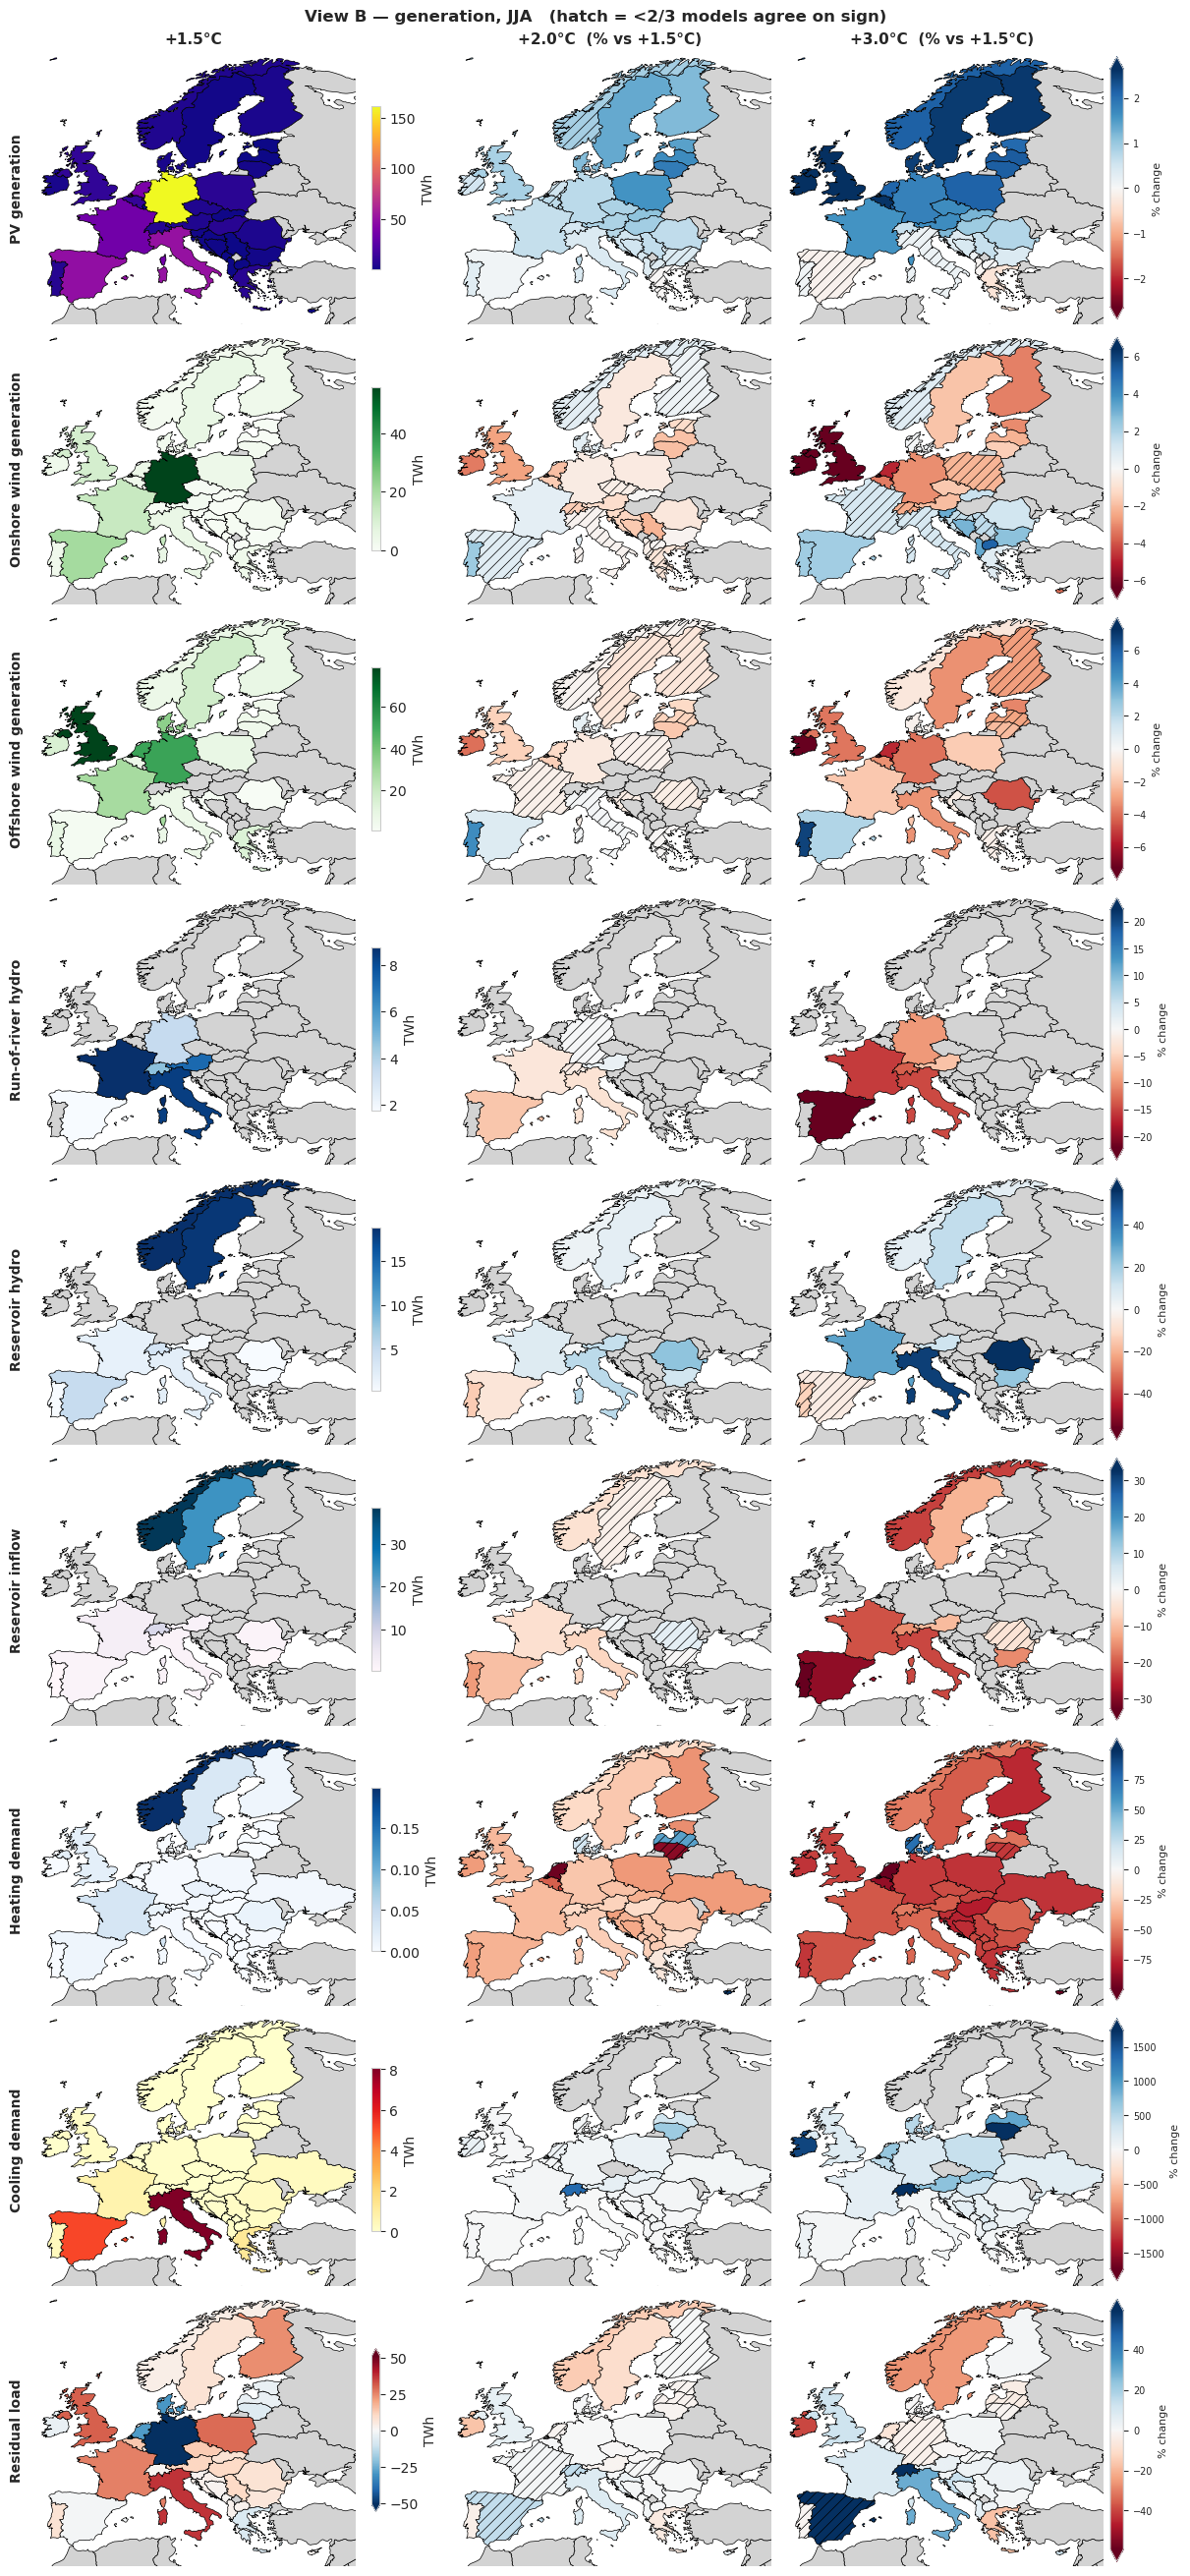

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((

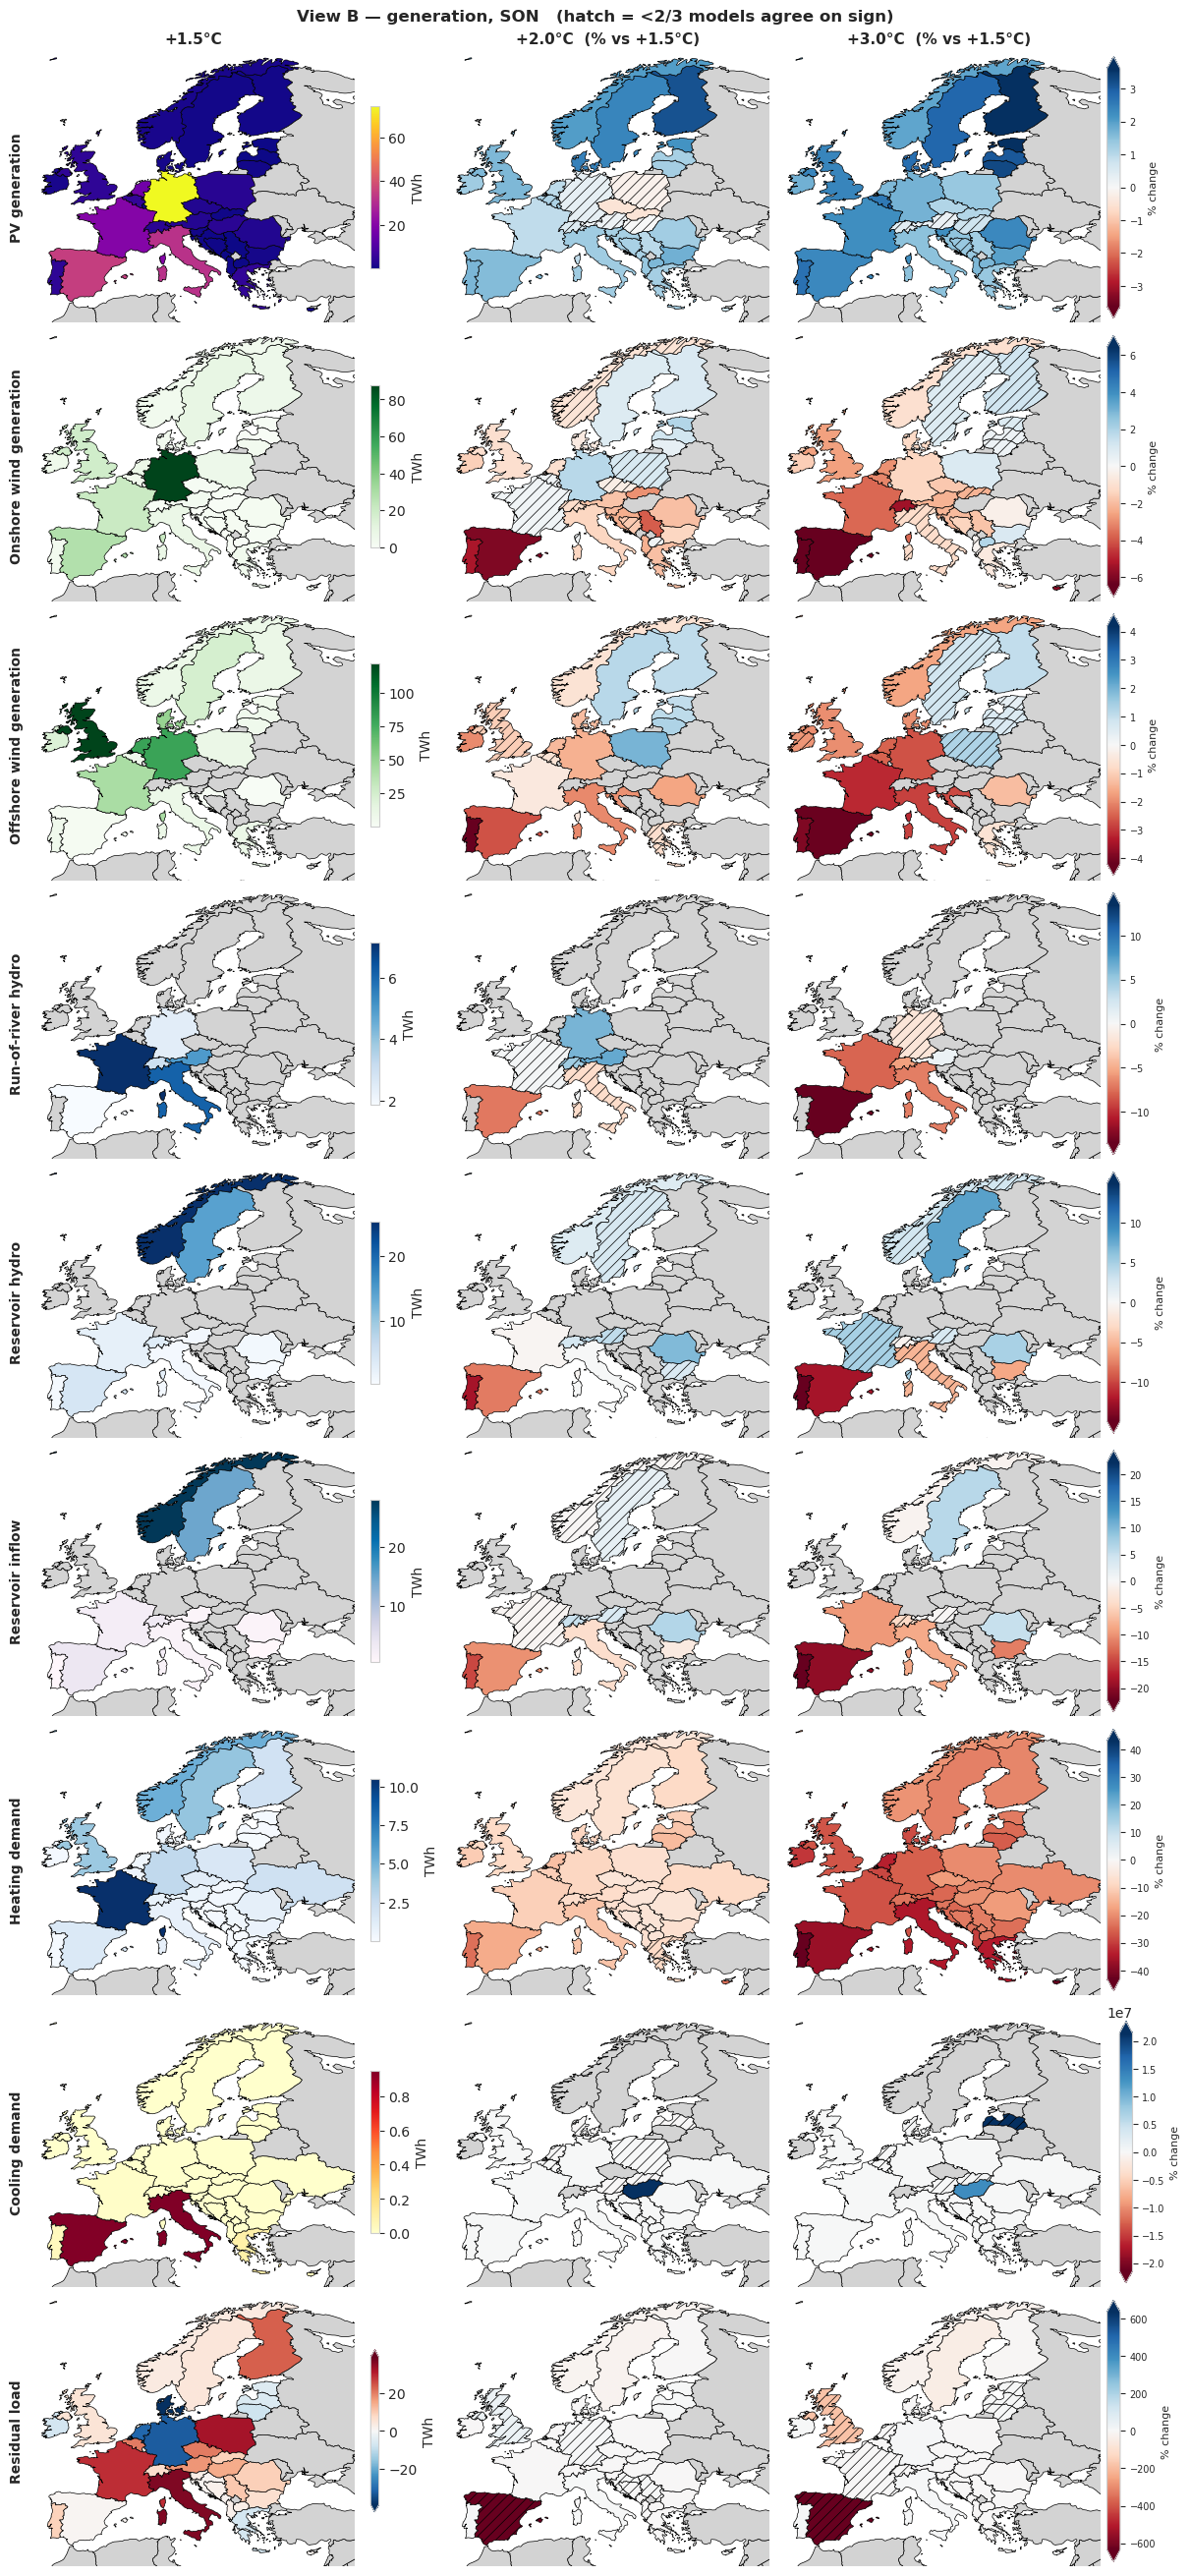

In [14]:
for _s in season_order:
    plot_gwl_grid(_QUANTS_B, "seasonal", season=_s, suptitle=f"View B — generation, {_s}")